# Download Dataset

In [ ]:
!pip -q install awscli

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sphinx 8.2.3 requires docutils<0.22,>=0.20, but you have docutils 0.19 which is incompatible.


In [ ]:
!aws s3 sync \
  --no-sign-request \
  s3://physionet-open/sleep-edfx/1.0.0/ \
  /content/sleep-edf/

download: s3://physionet-open/sleep-edfx/1.0.0/RECORDS-v1 to sleep-edf/RECORDS-v1  
download: s3://physionet-open/sleep-edfx/1.0.0/SC-subjects.xls to sleep-edf/SC-subjects.xls
download: s3://physionet-open/sleep-edfx/1.0.0/sleep-cassette/SC4001EC-Hypnogram.edf to sleep-edf/sleep-cassette/SC4001EC-Hypnogram.edf
download: s3://physionet-open/sleep-edfx/1.0.0/sleep-cassette/SC4002EC-Hypnogram.edf to sleep-edf/sleep-cassette/SC4002EC-Hypnogram.edf
download: s3://physionet-open/sleep-edfx/1.0.0/RECORDS to sleep-edf/RECORDS          
download: s3://physionet-open/sleep-edfx/1.0.0/ST-subjects.xls to sleep-edf/ST-subjects.xls
download: s3://physionet-open/sleep-edfx/1.0.0/sleep-cassette/SC4011EH-Hypnogram.edf to sleep-edf/sleep-cassette/SC4011EH-Hypnogram.edf
download: s3://physionet-open/sleep-edfx/1.0.0/SHA256SUMS.txt to sleep-edf/SHA256SUMS.txt
download: s3://physionet-open/sleep-edfx/1.0.0/sleep-cassette/SC4012EC-Hypnogram.edf to sleep-edf/sleep-cassette/SC4012EC-Hypnogram.edf
download: s3

# Imports

In [ ]:
!pip install mne

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.7/7.7 MB 127.8 MB/s  0:00:00
  Attempting uninstall: decorator
    Found existing installation: decorator 4.4.2
    Uninstalling decorator-4.4.2:
      Successfully uninstalled decorator-4.4.2
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [mne]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.2 which is incompatible.


In [ ]:
import os
from glob import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne

import torch
import torch.nn as nn

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, classification_report

#Data Loading

In [ ]:
data_dir = '/content/sleep-edf/sleep-cassette'

psg_files = sorted(glob(os.path.join(data_dir, '*PSG.edf')))
hypnogram_files = sorted(glob(os.path.join(data_dir, '*Hypnogram.edf')))

In [ ]:
psg_files[:3]

['/content/sleep-edf/sleep-cassette/SC4001E0-PSG.edf',
 '/content/sleep-edf/sleep-cassette/SC4002E0-PSG.edf',
 '/content/sleep-edf/sleep-cassette/SC4011E0-PSG.edf']

In [ ]:
hypnogram_files[:3]

['/content/sleep-edf/sleep-cassette/SC4001EC-Hypnogram.edf',
 '/content/sleep-edf/sleep-cassette/SC4002EC-Hypnogram.edf',
 '/content/sleep-edf/sleep-cassette/SC4011EH-Hypnogram.edf']

# Data Exploration

In [ ]:
raw_edf = mne.io.read_raw_edf(psg_files[0], preload=True, verbose=False)
raw_edf

/tmp/ipykernel_3001/2073790696.py:1: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw_edf = mne.io.read_raw_edf(psg_files[0], preload=True, verbose=False)
/tmp/ipykernel_3001/2073790696.py:1: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw_edf = mne.io.read_raw_edf(psg_files[0], preload=True, verbose=False)
/tmp/ipykernel_3001/2073790696.py:1: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw_edf = mne.io.read_raw_edf(psg_files[0], preload=True, verbose=False)


<RawEDF | SC4001E0-PSG.edf, 7 x 7950000 (79500.0 s), ~424.6 MiB, data loaded>

In [ ]:
eeg_data = raw_edf.get_data()
eeg_data

array([[ 5.01684982e-06, -2.57875458e-06,  1.35970696e-06, ...,
         5.29816850e-06, -4.64175824e-06,  6.61098901e-06],
       [-2.46739927e-06,  1.46739927e-06, -4.09890110e-06, ...,
        -3.04322344e-06, -3.71501832e-06,  1.75531136e-06],
       [ 1.65086691e-05,  1.60158730e-05,  9.60952381e-06, ...,
         6.97306471e-05,  8.05721612e-05,  1.02255189e-04],
       ...,
       [ 3.55200000e-06,  3.55321564e-06,  3.55442478e-06, ...,
         3.54832977e-06,  3.54955549e-06,  3.55077942e-06],
       [ 3.72064516e+01,  3.72051596e+01,  3.72039072e+01, ...,
         3.72105629e+01,  3.72091535e+01,  3.72077830e+01],
       [ 9.20000000e+02,  9.19950203e+02,  9.19892908e+02, ...,
         9.20104028e+02,  9.20076946e+02,  9.20042260e+02]],
      shape=(7, 7950000))

In [ ]:
eeg_chanel1 = eeg_data[0]

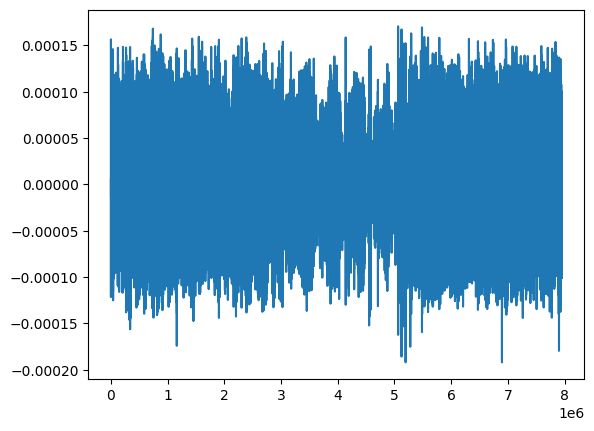

In [ ]:
plt.plot(eeg_chanel1)

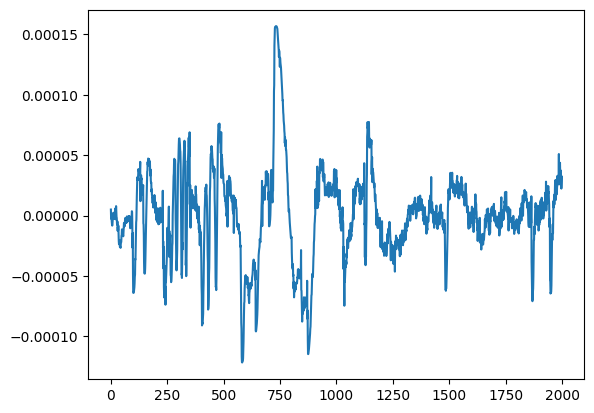

In [ ]:
plt.plot(eeg_chanel1[:2000])

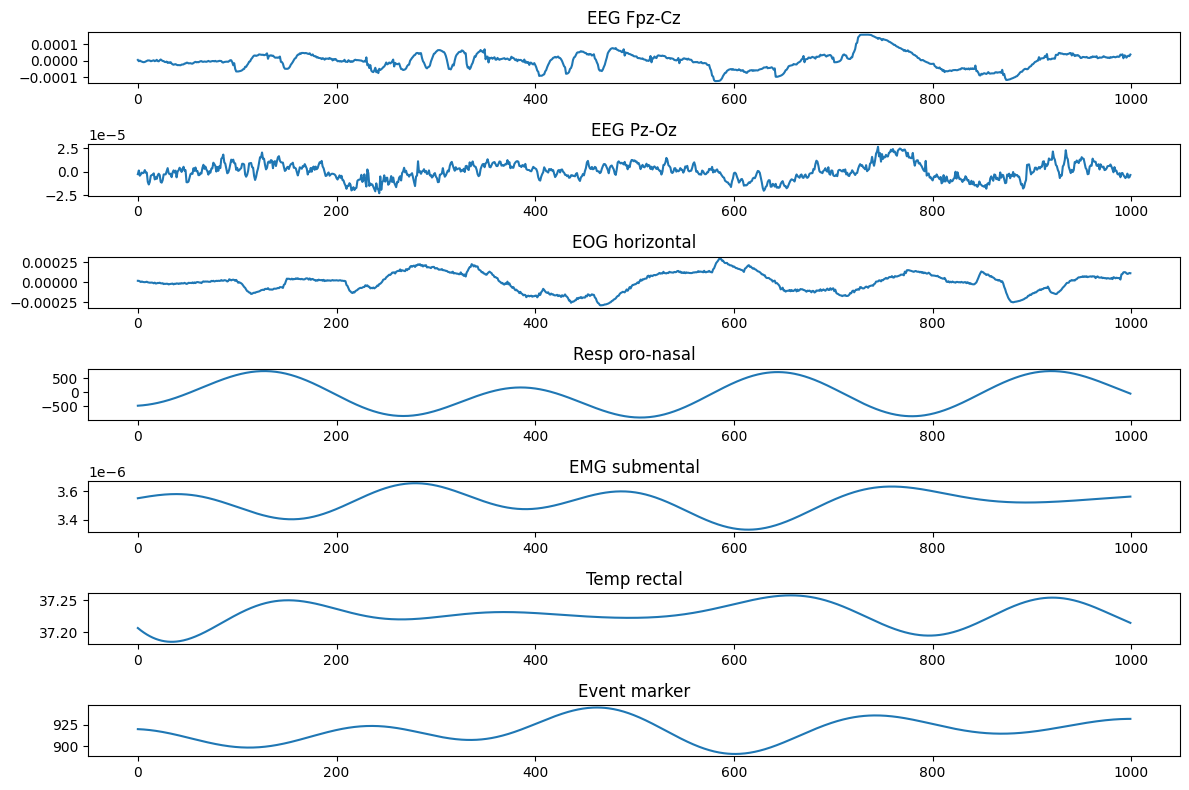

In [ ]:
fig, axis = plt.subplots(nrows=7, ncols=1, figsize=(12,8))

for i, ax in enumerate(axis):
  ax.plot(eeg_data[i][:1000])
  ax.set_title(raw_edf.ch_names[i])

plt.tight_layout()
plt.show()

In [ ]:
eeg_chanels = ['EEG Fpz-Cz','EEG Pz-Oz']
eeg_data = raw_edf.get_data(picks=eeg_chanels)

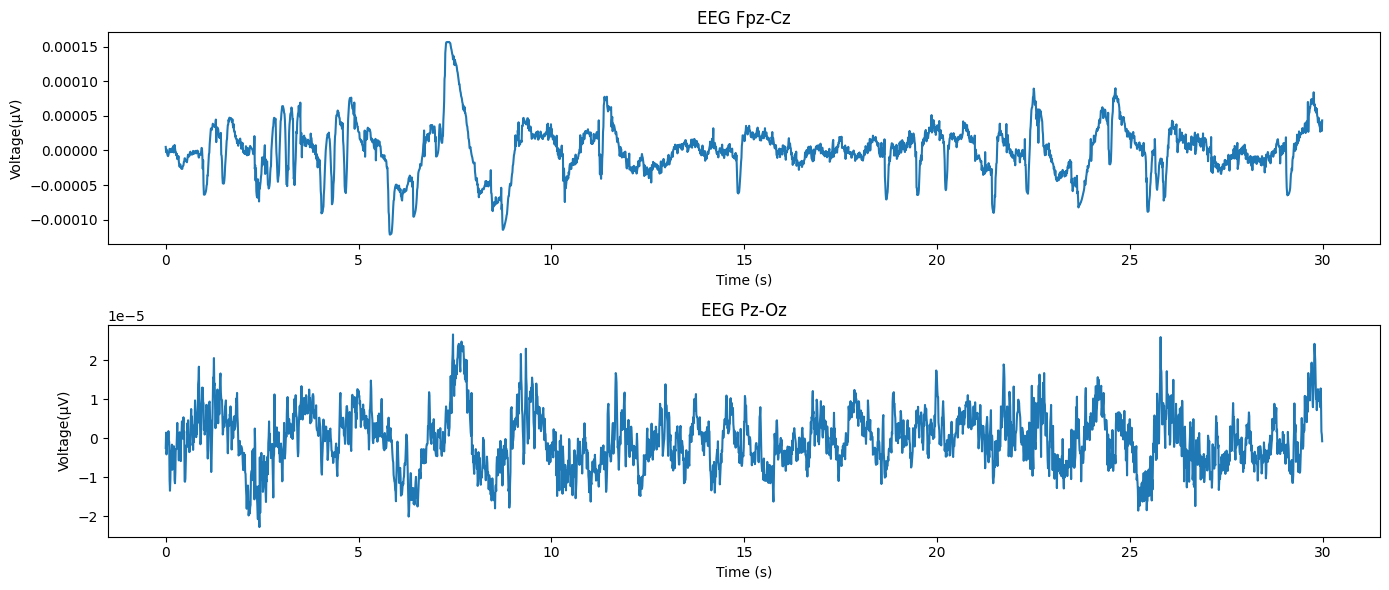

In [ ]:
fig, axis = plt.subplots(nrows=2, ncols=1, figsize=(14,6))

fs = 100
N = 3000
for i, ax in enumerate(axis):
  x = np.arange(N)/fs
  ax.plot(x, eeg_data[i][:N])
  ax.set_title(eeg_chanels[i])
  ax.set_xlabel('Time (s)')
  ax.set_ylabel('Voltage(μV)')

plt.tight_layout()
plt.show()

In [ ]:
annotations = mne.read_annotations(hypnogram_files[0])
annotations

<Annotations | 154 segments: Sleep stage 1 (24), Sleep stage 2 (40), Sleep ...>

In [ ]:
annotations.onset

array([    0., 30630., 30750., 31140., 31170., 31200., 31350., 31380.,
       31440., 31500., 31530., 31650., 31680., 31800., 31830., 31890.,
       31950., 32070., 32100., 32130., 32250., 32460., 32490., 32550.,
       32670., 32700., 32850., 32910., 32940., 32970., 33000., 33120.,
       33270., 33300., 33330., 33390., 33420., 33510., 35400., 35430.,
       35640., 35700., 35790., 35940., 35970., 36840., 37020., 37260.,
       37290., 37410., 37500., 37530., 38460., 38490., 38520., 38580.,
       38610., 38640., 38670., 38700., 38730., 38760., 38910., 38970.,
       39060., 39120., 39150., 39180., 39240., 39300., 39480., 39540.,
       39570., 39600., 39870., 39900., 39960., 39990., 40200., 40230.,
       40290., 40320., 40500., 41370., 41400., 41460., 41490., 41610.,
       42480., 42510., 42540., 42570., 42870., 42900., 43290., 43320.,
       43350., 43380., 43410., 43590., 43680., 43710., 43920., 43980.,
       44010., 44040., 44220., 44280., 44340., 44400., 44520., 44640.,
      

In [ ]:
annotations.description

array(['Sleep stage W', 'Sleep stage 1', 'Sleep stage 2', 'Sleep stage 3',
       'Sleep stage 2', 'Sleep stage 3', 'Sleep stage 4', 'Sleep stage 3',
       'Sleep stage 4', 'Sleep stage 3', 'Sleep stage 4', 'Sleep stage 3',
       'Sleep stage 4', 'Sleep stage W', 'Sleep stage 3', 'Sleep stage 2',
       'Sleep stage 3', 'Sleep stage 4', 'Sleep stage 3', 'Sleep stage 4',
       'Sleep stage 2', 'Sleep stage 3', 'Sleep stage 2', 'Sleep stage 3',
       'Sleep stage 1', 'Sleep stage 2', 'Sleep stage 3', 'Sleep stage 2',
       'Sleep stage 3', 'Sleep stage 2', 'Sleep stage 3', 'Sleep stage 4',
       'Sleep stage 3', 'Sleep stage 2', 'Sleep stage 3', 'Sleep stage 4',
       'Sleep stage 3', 'Sleep stage 4', 'Sleep stage 1', 'Sleep stage 3',
       'Sleep stage 2', 'Sleep stage 3', 'Sleep stage 2', 'Sleep stage 3',
       'Sleep stage R', 'Sleep stage 1', 'Sleep stage 2', 'Sleep stage 3',
       'Sleep stage 1', 'Sleep stage 2', 'Sleep stage 1', 'Sleep stage 2',
       'Sleep stage 3', '

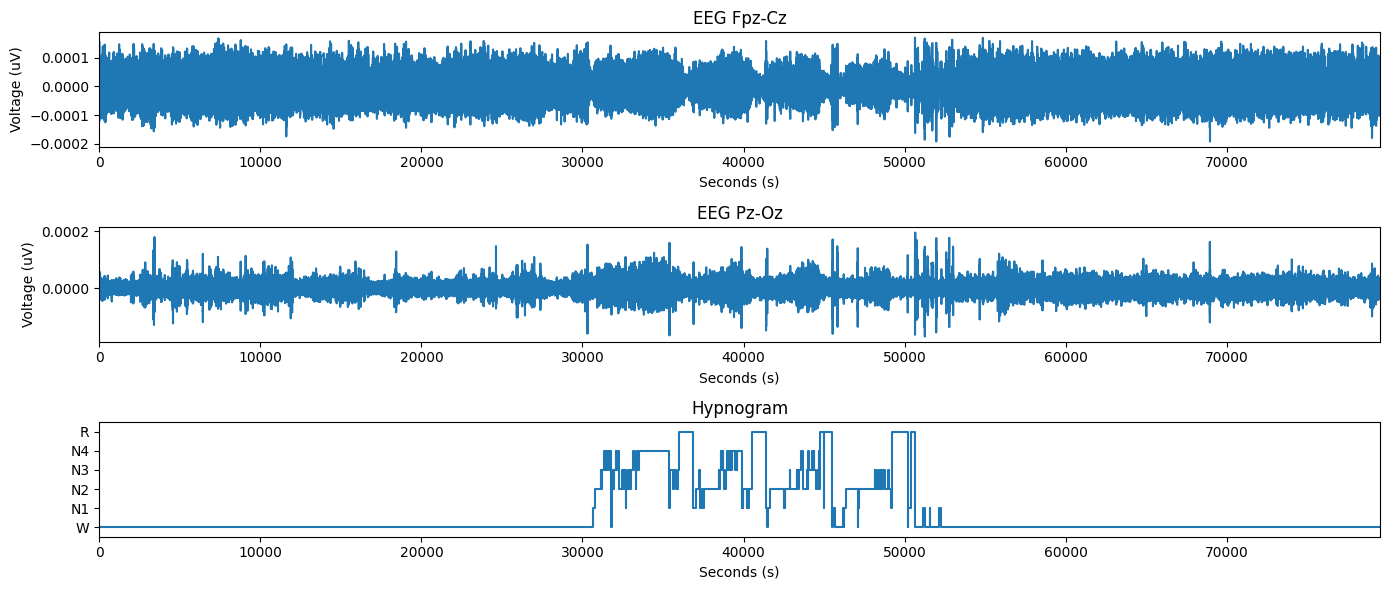

In [ ]:
fig, axs = plt.subplots(nrows=3, ncols=1, figsize=(14,6))

fs = 100
N = 7950000

x = np.arange(N) / fs

axs[0].plot(x, eeg_data[0][:N])
axs[0].set_title(eeg_chanels[0])
axs[0].set_xlabel('Seconds (s)')
axs[0].set_ylabel('Voltage (uV)')

axs[0].set_xlim(0, N/fs)

x = np.arange(N) / fs

axs[1].plot(x, eeg_data[1][:N])
axs[1].set_title(eeg_chanels[1])
axs[1].set_xlabel('Seconds (s)')
axs[1].set_ylabel('Voltage (uV)')

axs[1].set_xlim(0, N/fs)

t_end = N / fs

stage_map = {'Sleep stage W': 0, 'Sleep stage 1': 1, 'Sleep stage 2': 2, 'Sleep stage 3': 3, 'Sleep stage 4': 4, 'Sleep stage R': 5}

x, y = [], []
for o, d, s in zip(annotations.onset, annotations.duration, annotations.description):
    start, end = max(o, 0), min(o + d, t_end)
    stage = stage_map.get(s, np.nan)
    x += [start, end]
    y += [stage, stage]

axs[2].step(x, y, where='post')
axs[2].set_xlim(0, t_end)
axs[2].set_ylim(-0.5, 5.5)
axs[2].set_yticks([0,1,2,3,4,5])
axs[2].set_yticklabels(['W','N1','N2','N3', 'N4', 'R'])
axs[2].set_xlabel('Seconds (s)')
axs[2].set_title('Hypnogram')

plt.tight_layout()

# Data Preparation

In [ ]:
len(psg_files)

153

In [ ]:
X_data = []
y_data = []
groups = []
window_length = 3000

for psg_file, hypnogram_file in zip(psg_files[:25], hypnogram_files[:25]):
  raw_edf = mne.io.read_raw_edf(psg_file, preload=True, verbose=False)
  eeg_chanel1 = raw_edf.get_data(picks='EEG Fpz-Cz')[0]

  annotations = mne.read_annotations(hypnogram_file)

  # Extract subject ID from the file name (e.g., 'SC4001')
  subject_id = os.path.basename(psg_file)[:6]

  stage_map={'Sleep stage W': 0, 'Sleep stage 1': 1, 'Sleep stage 2': 2, 'Sleep stage 3': 3, 'Sleep stage 4': 4, 'Sleep stage R': 5}

  for i, (onset, duration, description) in enumerate(zip(annotations.onset, annotations.duration, annotations.description)):
    if description not in stage_map:
      continue

    for segment in range(int(onset*fs), int((onset + duration)*fs), window_length):
      start_sample = segment
      end_sample = segment + window_length

      if end_sample <= len(eeg_chanel1):
        window = eeg_chanel1[start_sample:end_sample]

        if len(window) == window_length:
          X_data.append(window)
          y_data.append(stage_map[description])
          groups.append(subject_id)

X = np.array(X_data)
y = np.array(y_data)
groups = np.array(groups)

/tmp/ipykernel_3001/1829761909.py:7: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw_edf = mne.io.read_raw_edf(psg_file, preload=True, verbose=False)
/tmp/ipykernel_3001/1829761909.py:7: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw_edf = mne.io.read_raw_edf(psg_file, preload=True, verbose=False)
/tmp/ipykernel_3001/1829761909.py:7: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw_edf = mne.io.read_raw_edf(psg_file, preload=True, verbose=False)
/tmp/ipykernel_3001/1829761909.py:7: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw_edf = mne.io.read_raw_edf(psg_file, preload=True, verbose=False)
/tmp/ipykernel_3001/1829761909.py:7: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw_edf

In [ ]:
X.shape

(68180, 3000)

In [ ]:
y.shape

(68180,)

In [ ]:
X = (X-X.mean()) / X.std()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [ ]:
X_train = torch.FloatTensor(X_train).unsqueeze(1).to(device)
y_train = torch.LongTensor(y_train).to(device)
X_test = torch.FloatTensor(X_test).unsqueeze(1).to(device)
y_test = torch.LongTensor(y_test).to(device)


# Model

In [ ]:
model = nn.Sequential(
    nn.Conv1d(1,32, kernel_size=50, stride=6),
    nn.ReLU(),
    nn.MaxPool1d(8),
    nn.Conv1d(32, 64, kernel_size=8),
    nn.ReLU(),
    nn.MaxPool1d(8),
    nn.Flatten(),
    nn.Linear(384, 128),
    nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(128, 6)
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# Training

In [ ]:
epochs = 10
batch_size = 64

for epoch in range(epochs):
  model.train()
  total_loss = 0
  for i in range(0, len(X_train), batch_size):
    X_batch = X_train[i:i+batch_size].to(device)
    y_batch = y_train[i:i+batch_size].to(device)

    optimizer.zero_grad()

    y_pred = model(X_batch)
    loss = criterion(y_pred, y_batch)
    loss.backward()
    optimizer.step()

    total_loss += loss.item()
  print(f'Epoch {epoch+1}/{epochs}, Loss: {total_loss/len(X_train)}')

Epoch 1/10, Loss: 0.020781088908639694
Epoch 2/10, Loss: 0.016663696795475007
Epoch 3/10, Loss: 0.011855955207343815
Epoch 4/10, Loss: 0.01004140451557219
Epoch 5/10, Loss: 0.009375260635170498
Epoch 6/10, Loss: 0.007781436356300917
Epoch 7/10, Loss: 0.006517196830789377
Epoch 8/10, Loss: 0.006060587747468653
Epoch 9/10, Loss: 0.005769897187926276
Epoch 10/10, Loss: 0.00547089359063686


In [ ]:
from sklearn.metrics import accuracy_score

model.eval()
with torch.no_grad():
  y_pred = model(X_test)
  y_pred_class = torch.argmax(y_pred, dim=1).cpu().numpy()

accuracy = accuracy_score(y_test.cpu().numpy(), y_pred_class)
accuracy

0.8637399808809472

In [ ]:
from sklearn.metrics import confusion_matrix

confusion_matrix(y_test.cpu().numpy(), y_pred_class)

array([[9384,    0,    4,    1,    0,   11],
       [ 262,    0,   23,    2,    0,  137],
       [  94,    0, 1519,   36,    0,  495],
       [  36,    0,  184,  288,    0,    0],
       [  16,    0,    3,  321,    0,    0],
       [ 169,    0,   59,    0,    0,  555]])